# Three-model comparison on the baseline predictors

**Owner:** Leonard. **Question:** how do three classical classifiers perform when given the same baseline information?

We compare **logistic regression**, **random forest**, and **histogram gradient boosting**, using all **32 currently implemented numeric predictors** (`team` + `timeline`). No new features or optional feature selection are introduced. Constants are removed inside each training fold.

Every candidate uses the same **five stratified development folds**, the same seed, and the same accuracy metric. Imputation and preprocessing are fitted inside folds. This notebook performs **CV comparisons only**: it never evaluates the local holdout, reads official test features, trains a final all-data model, or generates a submission.

These fixed starting settings are not a hyperparameter search. The goal is to establish comparable model references before feature engineering. A higher mean on five folds is useful evidence, not proof of a decisive difference.

In [1]:
from pathlib import Path
from datetime import datetime
from dataclasses import asdict
import json
import sys
import numpy as np
import pandas as pd

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "src/pokemon_challenge").is_dir()), None)
if ROOT is None:
    raise RuntimeError("Run this notebook inside the project repository.")
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))
from pokemon_challenge.experiment import BattleExperiment, Candidate
from pokemon_challenge.features.basic import team_stats, timeline_summary

OWNER = "leonard"
RUN = datetime.now().strftime("%Y%m%d_%H%M%S_%f_three_model_comparison")
experiment = BattleExperiment(
    owner=OWNER, run=RUN,
    feature_functions={"team": team_stats, "timeline": timeline_summary},
)
print("All numeric input predictors:", experiment.X.shape[1])
print("Validation settings:", experiment.validation)
display(experiment.assignments.groupby(["partition", "validation_fold"]).size().rename("battles").to_frame())


10,000 battles | 8,000 development | 2,000 holdout | 5 folds
Artifacts: /Users/leo/Library/CloudStorage/OneDrive-Persönlich/3_Programming/Workspaces/Erasmus/FDS/Pokemon/FDS_Challenge_26/outputs/leonard/20261029_150513_635611_three_model_comparison
All numeric input predictors: 32
Validation settings: {'seed': 42, 'metric': 'accuracy', 'splitter': 'StratifiedKFold', 'n_splits': 5, 'shuffle': True, 'holdout_size': 0.2}


battles
partition   validation_fold         
development  0                  1600
             1                  1600
             2                  1600
             3                  1600
             4                  1600
holdout     -1                  2000

## 1. Fix the features and the model settings

All three models get identical feature groups. `percentile=100` disables optional ANOVA selection. The shared pipeline imputes missing values and removes constants for every model; logistic regression additionally receives standard scaling.

The random forest uses 200 trees and a minimum of five samples per leaf. The boosting model uses 100 iterations, at most 15 leaves per tree, and L2 regularization. Early stopping is explicitly disabled so all fold-training rows are available to the estimator. These are fixed starting choices, not tuned settings.

In [2]:
candidates = [
    Candidate(
        "logistic_regression", groups=("team", "timeline"),
        model="logistic_regression", percentile=100,
        params={"C": 1.0, "solver": "lbfgs", "max_iter": 2000},
    ),
    Candidate(
        "random_forest", groups=("team", "timeline"),
        model="random_forest", percentile=100,
        params={"n_estimators": 200, "max_depth": None, "min_samples_leaf": 5, "n_jobs": 1},
    ),
    Candidate(
        "hist_gradient_boosting", groups=("team", "timeline"),
        model="hist_gradient_boosting", percentile=100,
        params={"max_iter": 100, "max_leaf_nodes": 15, "learning_rate": 0.1,
                "l2_regularization": 1.0, "early_stopping": False},
    ),
]
settings = pd.DataFrame([{
    "candidate": c.name, "groups": ", ".join(c.groups),
    "feature_selection_percentile": c.percentile, "model_parameters": json.dumps(c.params),
    "random_state": experiment.validation["seed"],
} for c in candidates])
pd.set_option("display.max_colwidth", 180)
display(settings)
print("Feature columns:")
display(pd.DataFrame({"predictor": list(experiment.X)}))


,candidate,groups,feature_selection_percentile,model_parameters,random_state
0,logistic_regression,"team, timeline",100,"{""C"": 1.0, ""solver"": ""lbfgs"", ""max_iter"": 2000}",42
1,random_forest,"team, timeline",100,"{""n_estimators"": 200, ""max_depth"": null, ""min_samples_leaf"": 5, ""n_jobs"": 1}",42
2,hist_gradient_boosting,"team, timeline",100,"{""max_iter"": 100, ""max_leaf_nodes"": 15, ""learning_rate"": 0.1, ""l2_regularization"": 1.0, ""early_stopping"": false}",42


Feature columns:


,predictor
0,team__p1_mean_atk
1,team__p1_mean_def
2,team__p1_mean_hp
3,team__p1_mean_spa
4,team__p1_mean_spd
5,team__p1_mean_spe
6,team__p2_lead_atk
7,team__p2_lead_def
8,team__p2_lead_hp
9,team__p2_lead_spa


## 2. Train each candidate on the same five folds

For 10,000 labelled battles, 2,000 remain in the reserved holdout. Each CV model trains on 6,400 development battles and validates on 1,600, repeating five times. The majority-class reference uses the same validation folds.

`cv_accuracy` is the mean validation accuracy. `fold_std` is the standard deviation of those five scores, **not a confidence interval**. Fit timings are machine-dependent and exclude feature extraction and scoring.

In [3]:
results = experiment.compare(candidates)
display(results)
fold_columns = [f"fold_{i+1}" for i in range(len(experiment.folds))]
fold_results = results.set_index("candidate")[fold_columns].T
fold_results.index.name = "validation_fold"
print("Paired fold scores (the columns use identical validation battles):")
display(fold_results)
print("Majority-class reference:", f"{results['dummy_accuracy'].iloc[0]:.2%}")


Validating logistic_regression on 5 folds...
Validating random_forest on 5 folds...
Validating hist_gradient_boosting on 5 folds...


,candidate,model,groups,input_features,percentile,mean_selected_features,cv_accuracy,fold_std,mean_fit_seconds,dummy_accuracy,fold_1,fold_2,fold_3,fold_4,fold_5
0,random_forest,random_forest,"team, timeline",32,100,30.0,0.615625,0.004312,1.158718,0.5,0.614375,0.61000,0.620625,0.620625,0.612500
1,hist_gradient_boosting,hist_gradient_boosting,"team, timeline",32,100,30.0,0.608375,0.003000,0.089767,0.5,0.608750,0.60625,0.613750,0.605000,0.608125
2,logistic_regression,logistic_regression,"team, timeline",32,100,30.0,0.605125,0.012199,0.011877,0.5,0.601250,0.59875,0.615000,0.622500,0.588125


Paired fold scores (the columns use identical validation battles):


candidate,random_forest,hist_gradient_boosting,logistic_regression
validation_fold,,,
fold_1,0.614375,0.608750,0.601250
fold_2,0.610000,0.606250,0.598750
fold_3,0.620625,0.613750,0.615000
fold_4,0.620625,0.605000,0.622500
fold_5,0.612500,0.608125,0.588125


Majority-class reference: 50.00%


## 3. Compare fold-by-fold improvements over logistic regression

Looking at paired changes is more informative than comparing the averages alone, because every model faces the same validation battles. Positive differences favour the alternative model. The table expresses changes in **percentage points**.

Five overlapping training folds do not provide five independent experiments. Win counts and score differences are descriptive, not a statistical significance claim.

In [4]:
reference = fold_results["logistic_regression"]
delta_rows = []
for model in fold_results:
    if model == "logistic_regression": continue
    differences = (fold_results[model] - reference) * 100
    delta_rows.append({
        "model": model,
        "mean_delta_pp": differences.mean(),
        "smallest_delta_pp": differences.min(),
        "largest_delta_pp": differences.max(),
        "folds_better_than_logistic": int((differences > 0).sum()),
        "folds_equal_to_logistic": int(np.isclose(differences, 0).sum()),
    })
deltas = pd.DataFrame(delta_rows)
display(deltas.round(4))
print("Highest mean CV score:", experiment.best_candidate)
print("This is a provisional CV ranking; no holdout has been evaluated here.")


,model,mean_delta_pp,smallest_delta_pp,largest_delta_pp,folds_better_than_logistic,folds_equal_to_logistic
0,random_forest,1.050,-0.1875,2.4375,4,0
1,hist_gradient_boosting,0.325,-1.7500,2.0000,3,0


Highest mean CV score: random_forest
This is a provisional CV ranking; no holdout has been evaluated here.


## 4. Visual comparison

The first chart shows all five scores per model; the horizontal line is the majority-class reference. The second shows means with one fold standard deviation in each direction. Those bars visualize fold variation, not confidence intervals.

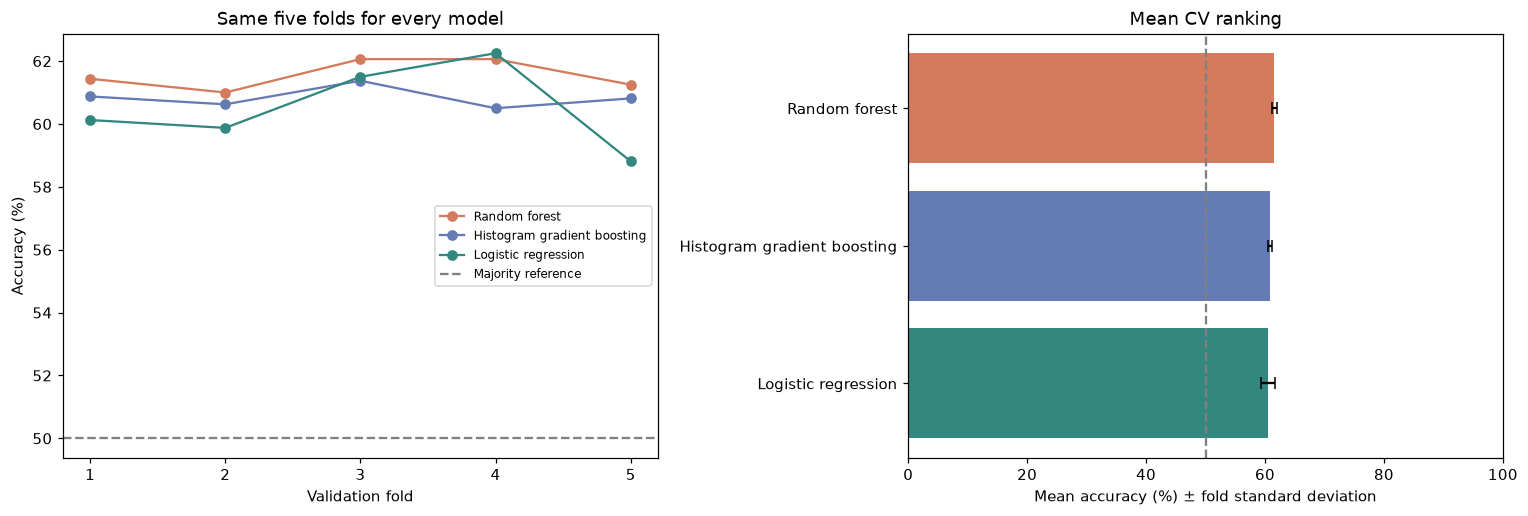

In [5]:
import matplotlib.pyplot as plt
colors = {"logistic_regression": "#32877f", "random_forest": "#d47b5e", "hist_gradient_boosting": "#657bb3"}
labels = {"logistic_regression": "Logistic regression", "random_forest": "Random forest", "hist_gradient_boosting": "Histogram gradient boosting"}
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
for model in fold_results:
    axes[0].plot(range(1, len(fold_results)+1), fold_results[model] * 100,
                 marker="o", label=labels[model], color=colors[model])
axes[0].axhline(results["dummy_accuracy"].iloc[0] * 100, color="gray", linestyle="--", label="Majority reference")
axes[0].set(xlabel="Validation fold", ylabel="Accuracy (%)", title="Same five folds for every model")
axes[0].set_xticks(range(1, len(fold_results)+1))
axes[0].legend(fontsize=8)
axes[1].barh([labels[m] for m in results["candidate"]], results["cv_accuracy"] * 100,
             xerr=results["fold_std"] * 100, color=[colors[m] for m in results["candidate"]], capsize=4)
axes[1].invert_yaxis()
axes[1].axvline(results["dummy_accuracy"].iloc[0] * 100, color="gray", linestyle="--")
axes[1].set(xlabel="Mean accuracy (%) ± fold standard deviation", title="Mean CV ranking", xlim=(0, 100))
fig.tight_layout()
display(fig)
plt.close(fig)


## 5. Verify a fair comparison and save a reference for feature engineering

The following checks confirm that all models used the same feature groups, that no optional selector was enabled, and that holdout/submission artifacts were not produced. We also compare the split hash against the most recent first logistic baseline when its local artifacts are available.

This check is about fold/data consistency, not proof that ordinary stratification handles every possible relationship between battles.

In [6]:
assert len(results) == 3
assert results["input_features"].nunique() == 1
assert results["percentile"].eq(100).all()
selection_tables = {c.name: pd.read_csv(experiment.output_path / f"selection_frequency_{c.name}.csv").set_index("feature") for c in candidates}
for name, table in selection_tables.items():
    pd.testing.assert_frame_equal(table, selection_tables["logistic_regression"])
print("Features retained in every fold:", int(selection_tables["logistic_regression"]["selected_in_folds"].eq(len(experiment.folds)).sum()))
print("Constant features removed:")
display(selection_tables["logistic_regression"].loc[lambda t: t["selected_in_folds"].eq(0)])
assert not (experiment.output_path / "holdout_metrics.json").exists()
assert not (experiment.output_path / "submission.csv").exists()
assert not (experiment.output_path / "model.joblib").exists()

prior = sorted((ROOT / "outputs/leonard").glob("*_logistic_all_features/experiment.json"))
prior_hash_matches = None
if prior:
    prior_manifest = json.loads(prior[-1].read_text())
    prior_hash_matches = prior_manifest["splits_sha256"] == experiment.manifest["splits_sha256"]
    print("Same assignments as the most recent first baseline:", prior_hash_matches)
else:
    print("No prior local baseline artifacts found; current assignments are saved in splits.csv.")

results.to_csv(experiment.output_path / "three_model_comparison.csv", index=False)
fold_results.to_csv(experiment.output_path / "paired_fold_scores.csv")
deltas.to_csv(experiment.output_path / "deltas_vs_logistic.csv", index=False)
summary = {
    "purpose": "fixed-feature, fixed-fold three-model reference before feature engineering",
    "feature_groups": ["team", "timeline"],
    "input_predictors": int(results["input_features"].iloc[0]),
    "n_folds": len(experiment.folds),
    "split_hash": experiment.manifest["splits_sha256"],
    "same_splits_as_prior_logistic_baseline": prior_hash_matches,
    "ranking": results[["candidate", "cv_accuracy", "fold_std", "mean_fit_seconds"]].to_dict(orient="records"),
    "holdout_evaluated": False,
    "submission_generated": False,
}
(experiment.output_path / "three_model_summary.json").write_text(json.dumps(summary, indent=2) + "\n")
print("Saved artifacts:", experiment.output_path)
for path in sorted(experiment.output_path.iterdir()): print(" -", path.name)


Features retained in every fold: 30
Constant features removed:


,selected_in_folds
feature,
team__team_size,0
timeline__observed_turns,0


Same assignments as the most recent first baseline: True
Saved artifacts: /Users/leo/Library/CloudStorage/OneDrive-Persönlich/3_Programming/Workspaces/Erasmus/FDS/Pokemon/FDS_Challenge_26/outputs/leonard/20261029_150513_635611_three_model_comparison
 - candidates.json
 - cv_results.csv
 - deltas_vs_logistic.csv
 - experiment.json
 - feature_sources.json
 - paired_fold_scores.csv
 - selection_frequency_hist_gradient_boosting.csv
 - selection_frequency_logistic_regression.csv
 - selection_frequency_random_forest.csv
 - splits.csv
 - three_model_comparison.csv
 - three_model_summary.json


## Next: controlled feature engineering

Use this run as the reference. Add one feature block, keep these model settings and fold assignments fixed, and rerun the same three candidates. Compare the new scores with this run **within each model**, not only the best score overall.

Suggested first block: each observed Pokémon's last recorded health and related coverage/missingness indicators. Treat unobserved Pokémon carefully: no observation does not imply zero HP. Decide the representation using training data and known observation mechanics.

Continue to use CV for development. Reserve any later holdout use for a deliberate final assessment; do not repeatedly tune against its result. Promote successful feature functions to the shared package and retain exact run settings/code before making a final submission.